# Usuarios de Netflix


## 1.Definición de Pregunta y Objetivos especificos

####1.1 Pregunta principal

* ¿Cuáles son las características de los usuarios actuales de Netflix en relación con su tipo de suscripción, género favorito y método de pago?







####1.2 Objetivos específicos

1.  Conocer qué tipo de suscripción es la mas frecuente entre los usuarios activos
2. Buscar cual es el genero mas visto en cada region por rango etario.
3. Detectar cuál es el metodo de pago mas elegido de cada region.






## 2.Carga y definición del DataSet
    

#### 2.1 Justificación del Data Set

El dataset seleccionado contiene información de usuarios de Netflix, incluyendo características demográficas, región, tipo de suscripción, dispositivo utilizado, método de pago, género favorito, etc. Se seleccionó este dataset porque permite analizar diferentes características de los usuarios activos y encontrar diferencias entre regiones y grupos etarios.

#### 2.2 Carga de datos

In [1]:
#Importo pandas y numpy para trabajar sobre el dataset.

import pandas as pd
import numpy as np

pd.__version__

'2.2.3'

In [2]:
#Cargo el archivo sobre el que voy a trabajar
df_ntx = pd.read_csv  ('netflix_usuarios.csv')

df_ntx

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi


In [3]:
# Obtener y listar todas las columnas del dataset para luego describirlas.
columnas_dataset = df_ntx.columns.tolist()
print("Columnas en el dataset:")
display(columnas_dataset)

Columnas en el dataset:


['customer_id',
 'age',
 'gender',
 'subscription_type',
 'watch_hours',
 'last_login_days',
 'region',
 'device',
 'monthly_fee',
 'churned',
 'payment_method',
 'number_of_profiles',
 'avg_watch_time_per_day',
 'favorite_genre']

In [4]:
# Descripción de las columnas en el dataset:

# customer_id = Identificador único de cada usuario
# age = Edad del usuario
# gender = Género del usuario.
# subscription_type = Tipo de suscripción del usuario
# watch_hours = Horas de visualización de contenido
# last_login_days = días desde la última conexión,
# region = Región geográfica del usuario
# device = Dispositivo utilizado por el usuario
# monthly_fee = Monto mensual de la suscripción
# churned = Refiere a si el usuario está activo o no.
# payment_method = Método de pago utilizado por el usuario
# number_of_profiles = Cantidad de perfiles utilizados por el usuario
# avg_watch_time_per_day = Promedio de tiempo de visualización por día
# favorite_genre = Género favorito del usuario

## 3.Análisis del Data Set
  

#### 3.1 Exploración cualitativa y cuantitativa de los datos




In [5]:
# Forma de los datos
df_ntx.shape     # Resultado: (filas,columnas)

(5000, 14)

In [6]:
# Tipos de datos de cada columna y existencia de nulos
df_ntx.info()

#El resultado indica que el dataset no posee nulos.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float64(3), int64(4), object(7)
memor

In [7]:
# Churned es un dato booleano.
# Transformo el tipo de dato:

df_ntx['churned'] = df_ntx['churned'].astype(bool)



In [8]:
# Verifico el cambio de tipo de dato.
df_ntx.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   bool   
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: bool(1), float64(3), int64(3), object

In [9]:
# Exploracion de cada columna de texto

print(df_ntx ["gender"].value_counts())
print()

print(df_ntx["subscription_type"].value_counts())
print()

print(df_ntx["region"].value_counts())
print()

print(df_ntx["device"].value_counts())
print()

print(df_ntx["payment_method"].value_counts())
print()

print(df_ntx["favorite_genre"].value_counts())
print()

#En este paso veo que no tengo errores de escritura ni categorias repetidas.

gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64

payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Name: count, dtype: int64

favorite_genre
Drama          731
Documentary    729
Romance        725
Sci-Fi         720
Horror         713
Action         697
Comedy         685
Name: count, dtype: int64



In [10]:
# Verifico filas duplicadas

df_ntx.duplicated().sum()

np.int64(0)

In [11]:
# Verifico si hay usuarios repetidos.

df_ntx["customer_id"].value_counts()

,count
customer_id,
82aeef39-ddb0-40ad-bae1-5c436e0cf042,1
a9b75100-82a8-427a-a208-72f24052884a,1
49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,1
4d71f6ce-fca9-4ff7-8afa-197ac24de14b,1
d3c72c38-631b-4f9e-8a0e-de103cad1a7d,1
...,...
4690bf9c-b828-44d3-bdb6-f91b10668288,1
9df43ad1-d6ee-44d0-a79b-c8ab444f10bf,1
45a03ce3-26d0-4cd5-a9bd-22d42490b612,1


In [12]:
# Filtro para ver si alguno de los valores es diferente a 1

conteo_id = df_ntx['customer_id'].value_counts()
conteo_id[conteo_id > 1]

# Confirmo que ningun ID está repetido


,count
customer_id,


In [13]:
# Busco cuantos de estos usuarios están inactivos y cuantos activos.
on_off = df_ntx['churned'].value_counts().to_frame('cantidad')
on_off['porcentaje'] = (on_off['cantidad'] / len(df_ntx) * 100).round(2)

on_off


,cantidad,porcentaje
churned,,
True,2515,50.3
False,2485,49.7


In [14]:
#  Para el análisis filtro solo los usuarios activos.

df_ntx[df_ntx['churned'] == True]

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,True,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,True,Gift Card,5,0.03,Sci-Fi
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,True,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,True,Crypto,2,0.13,Action
7,02387681-8c42-462a-807a-de0168c73b38,51,Male,Basic,14.30,56,Europe,Mobile,8.99,True,Gift Card,1,0.25,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4990,edb9036d-95f9-4998-9910-78ba85869dbd,57,Male,Standard,2.09,13,Asia,TV,13.99,True,Crypto,3,0.15,Romance
4992,9721209e-3147-456f-a2c0-81d23b4cf822,34,Male,Standard,10.25,41,Oceania,Desktop,13.99,True,Crypto,3,0.24,Documentary
4993,f915a366-31c7-4a9e-9042-ca526c771219,23,Other,Standard,3.10,12,Europe,Laptop,13.99,True,Crypto,5,0.24,Comedy
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,True,Debit Card,2,0.33,Action


In [15]:
# Datos estadisticos de las columnas numéricas solo con usuarios activos

df_ntx[df_ntx['churned'] == True].describe().round(2)

# Las columnas watch_hours y avg_watch_time_per_day contienen promedios por encima del valor al 50%, esto quiere decir que contienen valores extremos superiores.


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day
count,2515.00,2515.00,2515.00,2515.00,2515.00,2515.00
mean,43.79,5.92,38.31,13.13,2.80,0.16
std,15.47,5.42,14.75,3.76,1.38,0.19
min,18.00,0.01,0.00,8.99,1.00,0.00
25%,30.00,1.83,30.00,8.99,2.00,0.06
50%,44.00,4.06,41.00,13.99,3.00,0.12
75%,57.00,8.71,50.00,17.99,4.00,0.23
max,70.00,41.33,60.00,17.99,5.00,4.32


In [16]:
# Guardo el data set modificado solo con los valores de usuarios activos para el análisis.

data_set_limpio = df_ntx[df_ntx['churned'] == True]

data_set_limpio.to_csv('data_set_limpio.csv', index=False)

In [17]:
# Verifico que el data set se haya guardado correctamente.

df_dsl = pd.read_csv  ('data_set_limpio.csv')

df_dsl

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,True,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,True,Gift Card,5,0.03,Sci-Fi
2,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,True,Crypto,2,0.35,Horror
3,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,True,Crypto,2,0.13,Action
4,02387681-8c42-462a-807a-de0168c73b38,51,Male,Basic,14.30,56,Europe,Mobile,8.99,True,Gift Card,1,0.25,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2510,edb9036d-95f9-4998-9910-78ba85869dbd,57,Male,Standard,2.09,13,Asia,TV,13.99,True,Crypto,3,0.15,Romance
2511,9721209e-3147-456f-a2c0-81d23b4cf822,34,Male,Standard,10.25,41,Oceania,Desktop,13.99,True,Crypto,3,0.24,Documentary
2512,f915a366-31c7-4a9e-9042-ca526c771219,23,Other,Standard,3.10,12,Europe,Laptop,13.99,True,Crypto,5,0.24,Comedy
2513,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,True,Debit Card,2,0.33,Action


#### 3.2 Conclusiones de la exploracion:

*   El data set no tiene datos nulos.
*   Cada fila es un dato único.
*   Las variables categóricas presentan categorías consistentes, sin detectar valores que requieran una corrección de escritura.
*   Alrededor de la mitad de los datos son de usuarios que están inactivos.






#### 3.3 Búsqueda de resultados

##### 3.3.1 ¿Qué tipo de suscripción es la mas frecuente entre los usuarios activos?

In [18]:
# 1. Conozco cual es el tipo de susb
print(df_dsl["subscription_type"].value_counts())
print()

# A nivel general, el tipo de suscripcion mas elegida es la suscripción Básica

subscription_type
Basic       1027
Standard     748
Premium      740
Name: count, dtype: int64



##### 3.3.2 ¿Cual es el genero mas visto en cada region por rango etario?

In [19]:
# Defino los rangos de edad y etiquetas correspondientes

limites = [17, 40, 60, df_dsl['age'].max()]
etiquetas = ['18-40', '41-60', '60+']


# Agrego la columna de rango etario al dataset limpio
df_dsl['age_group'] = pd.cut(df_dsl['age'], bins=limites, labels=etiquetas)

# Verifico el agregado de la columna
df_dsl.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,age_group
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,True,Gift Card,1,0.49,Action,41-60
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,True,Gift Card,5,0.03,Sci-Fi,41-60
2,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,True,Crypto,2,0.35,Horror,41-60
3,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,True,Crypto,2,0.13,Action,41-60
4,02387681-8c42-462a-807a-de0168c73b38,51,Male,Basic,14.30,56,Europe,Mobile,8.99,True,Gift Card,1,0.25,Action,41-60


In [20]:
# Cuento los usuarios por región y grupo de edad
conteo_etario = df_dsl.groupby(['region', 'age_group'], observed=False).size().reset_index(name='cantidad')
display(conteo_etario)

,region,age_group,cantidad
0,Africa,18-40,168
1,Africa,41-60,144
2,Africa,60+,76
3,Asia,18-40,191
4,Asia,41-60,160
5,Asia,60+,75
6,Europe,18-40,189
7,Europe,41-60,171
8,Europe,60+,88
9,North America,18-40,187


In [21]:
# Agrupamos por región y grupo de edad, y obtenemos el género favorito más común (moda)
genero_por_region_etario = df_dsl.groupby(['region', 'age_group'], observed=False)['favorite_genre'].agg(lambda x: x.mode()[0] if not x.empty else None).reset_index(name='genero_mas_visto')

# Unimos este resultado con el conteo de usuarios previamente calculado para tener la vista completa
resumen_completo = pd.merge(conteo_etario, genero_por_region_etario, on=['region', 'age_group'])

display(resumen_completo)

,region,age_group,cantidad,genero_mas_visto
0,Africa,18-40,168,Drama
1,Africa,41-60,144,Documentary
2,Africa,60+,76,Comedy
3,Asia,18-40,191,Documentary
4,Asia,41-60,160,Comedy
5,Asia,60+,75,Sci-Fi
6,Europe,18-40,189,Drama
7,Europe,41-60,171,Sci-Fi
8,Europe,60+,88,Action
9,North America,18-40,187,Romance


##### 3.3.3 ¿Cuál es el metodo de pago mas elegido en cada region?

In [22]:
# Busco el metodo de pago mas frecuente por region
pago_por_region = df_dsl.groupby('region')['payment_method'].agg(lambda x: x.mode()[0] if not x.empty else None).reset_index(name='metodo_pago_mas_frecuente')
display(pago_por_region)

,region,metodo_pago_mas_frecuente
0,Africa,Crypto
1,Asia,Crypto
2,Europe,Gift Card
3,North America,Crypto
4,Oceania,Gift Card
5,South America,Crypto


## 4.Gráficas de resultados

In [23]:
# Importo galerías

import matplotlib.pyplot as plt
import seaborn as sns

#### 3.4.1 Tipo de suscripción elegida por usuarios activos

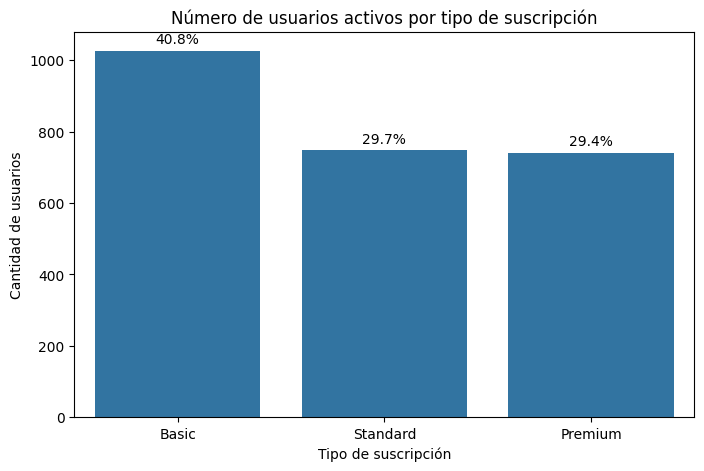

In [24]:
suscripciones = df_dsl['subscription_type'].value_counts()
porcentajes = (suscripciones / len(df_dsl) * 100).round(1)

plt.figure(figsize=(8,5))

sns.barplot(
    x=suscripciones.index,
    y=suscripciones.values
)

plt.title('Número de usuarios activos por tipo de suscripción')
plt.xlabel('Tipo de suscripción')
plt.ylabel('Cantidad de usuarios')

for i, valor in enumerate(suscripciones.values):
    plt.text(
        i,
        valor + 20,
        f'{porcentajes.iloc[i]}%',
        ha='center'
    )

plt.show()

La suscripción Basic es la más frecuente entre los usuarios activos, con 1.027 usuarios, mientras que Standard y Premium presentan cantidades similares, con 748 y 740 usuarios respectivamente. Esto muestra una mayor presencia del plan Basic dentro de los usuarios actuales analizados.

#### 3.4.2 Usuarios activos por región y rango etario

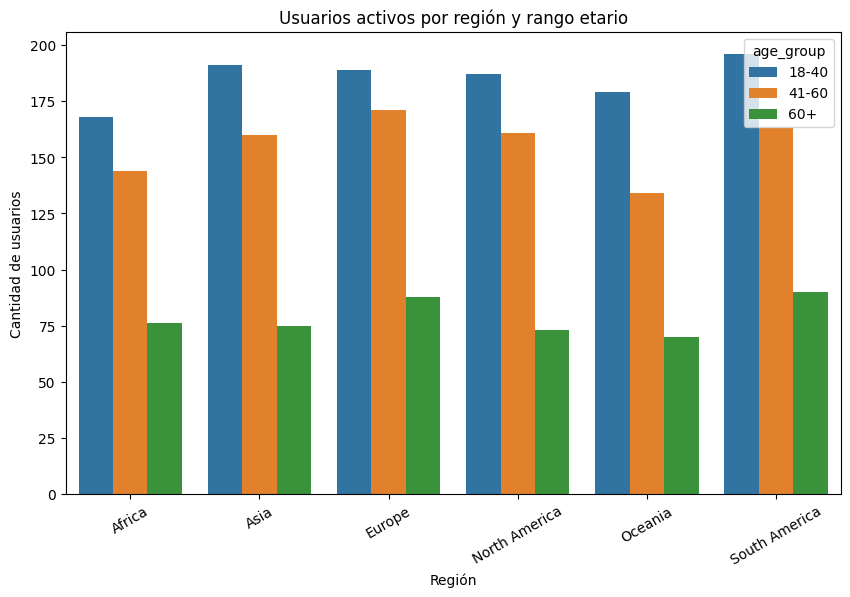

In [25]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=conteo_etario,
    x='region',
    y='cantidad',
    hue='age_group'
)

plt.title('Usuarios activos por región y rango etario')
plt.xlabel('Región')
plt.ylabel('Cantidad de usuarios')
plt.xticks(rotation=30)

plt.show()

En todas las regiones se observa mayor predominancia de usuarios mas jóvenes, entre 18 y 40 años.

 #### 3.4.3 Género favorito por región y rango etario

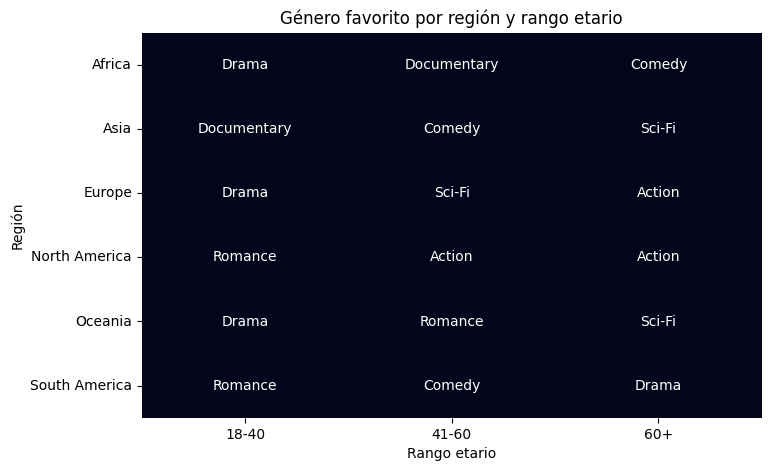

In [26]:
tabla_generos = resumen_completo.pivot(
    index='region',
    columns='age_group',
    values='genero_mas_visto'
)

plt.figure(figsize=(8,5))

sns.heatmap(
    tabla_generos.notna(),
    annot=tabla_generos,
    fmt='',
    cbar=False
)

plt.title('Género favorito por región y rango etario')
plt.xlabel('Rango etario')
plt.ylabel('Región')

plt.show()

El género favorito varía según la región y el rango etario.
Drama aparece como género predominante entre los usuarios mas jóvenes en África, Europa y Oceanía, mientras que en Norteamérica y Sudamérica predomina Romance para este grupo. En los usuarios de mayor edad, se observan diferentes preferencias según la región sin un género predominante.

#### 3.4.4 Métodos de pago mas utilizados por región

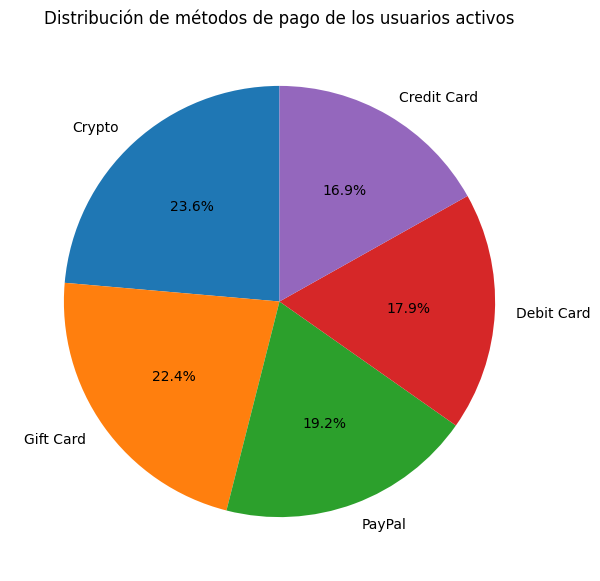

In [27]:
pago = df_dsl['payment_method'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    pago.values,
    labels=pago.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribución de métodos de pago de los usuarios activos')
plt.show()

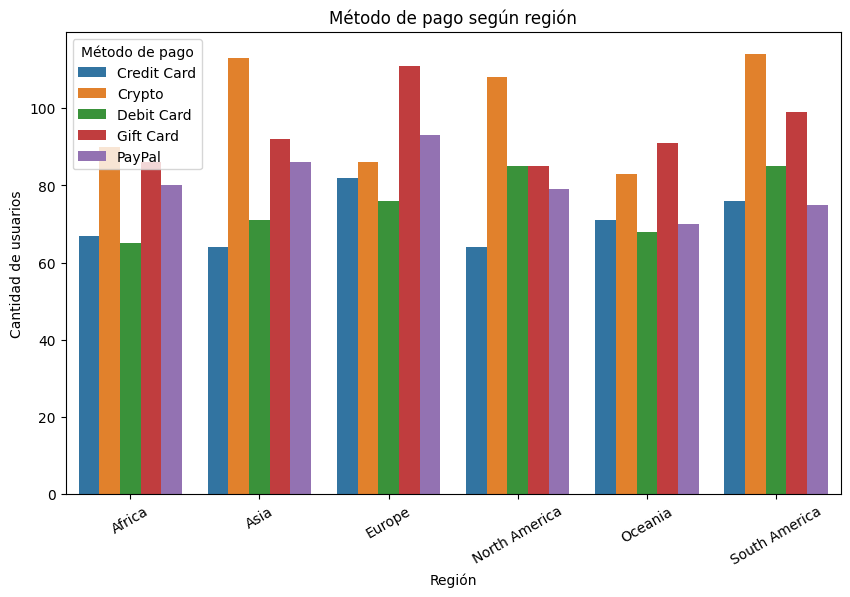

In [28]:
pago_region = (
    df_dsl
    .groupby(['region', 'payment_method'])
    .size()
    .reset_index(name='cantidad')
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=pago_region,
    x='region',
    y='cantidad',
    hue='payment_method'
)

plt.title('Método de pago según región')
plt.xlabel('Región')
plt.ylabel('Cantidad de usuarios')
plt.xticks(rotation=30)
plt.legend(title='Método de pago')

plt.show()

A partir del grafico se observa que los métodos de pago mas elgidos en todas las regiones son Crypto y Gift Card.